# Time Series - Synthetic series

A `TimeSeries` can make its own data, take a record apart, and estimate the parameters behind it. With these parameters, you can build new series: more realizations of the same process, or the same process with something changed. This tutorial goes through this cycle with daily temperature.

A series is the sum of three parts. The **Trend** is a straight line. The **Cycle** repeats every year. The **Remainder** is what is left, and it has two parts of its own: the **Memory**, which carries part of the previous step, and the **Shocks**, which are new and random at each step:

$$x_t = \text{Trend}_t + \text{Cycle}_t + \text{Remainder}_t, \qquad \text{Remainder}_t = \underbrace{\varphi \, \text{Remainder}_{t-1}}_{\text{Memory}} + \underbrace{\varepsilon_t}_{\text{Shocks}}, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$

Covered here:

- Generating a series from physical specs with `.generate()`
- Splitting a series into its parts with `.decompose()`
- Estimating the parameters with `.fit()`
- Building new series from fitted and perturbed parameters
- A Monte Carlo simulation with random realizations of the shocks

```{seealso}
Check out the {doc}`Stochastic series - AR(1) generator <stochastic_01_arma>` tutorial for the functions behind these methods, and the {doc}`Time Series - Collection visuals <timeseries_12_collection_views>` tutorial for the plots used here.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import numpy as np
import pandas as pd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

from plans.datasets import (
    TemperatureSeries,
    TimeSeries,
    TimeSeriesCollection,
    TimeSeriesEnsemble,
)
from plans.datasets.analyst import Univar

## Generate

Each series class has its own default specs in `.generator_specs`, in physical terms, so they apply to any time step. Here we add a warming trend to the defaults of the temperature:

In [2]:
ts = TemperatureSeries(name="Station")
ts.generator_specs["change_per_year"] = 0.1
ts.generator_specs

{'baseline': 18.0,
 'topline': 28.0,
 'peak_day': 15,
 'power': 1.0,
 'memory_days': 3.0,
 'remainder_sd': 1.5,
 'change_per_year': 0.1}

The `.generate()` method returns a dataframe by default. With `inplace=True`, the data goes into the object. A `seed` makes the result reproducible:

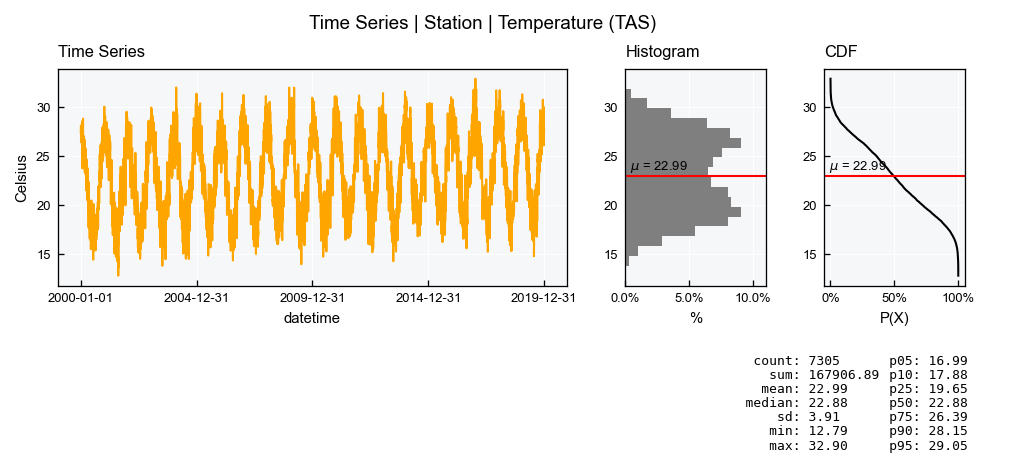

In [3]:
ts.generate(start="2000-01-01", end="2019-12-31", seed=1, inplace=True)
ts.view(show=True)

## Decompose

The `.decompose()` method splits the data into its parts, and returns a dataframe with one column for each. Without parameters, it estimates them from the data:

In [4]:
df_parts = ts.decompose()
df_parts.head()

,datetime,trend,cycle,remainder,shocks
0,2000-01-01,21.917108,4.934382,0.522693,0.522693
1,2000-01-02,21.917400,4.956947,1.232649,0.860207
2,2000-01-03,21.917693,4.978005,1.226689,0.348373
3,2000-01-04,21.917985,4.997550,-0.487571,-1.361641
4,2000-01-05,21.918278,5.015575,0.594260,0.941675


Stacked panels read naturally here. Note that each panel has its own y range, so read the values on the axes before comparing the size of the parts:

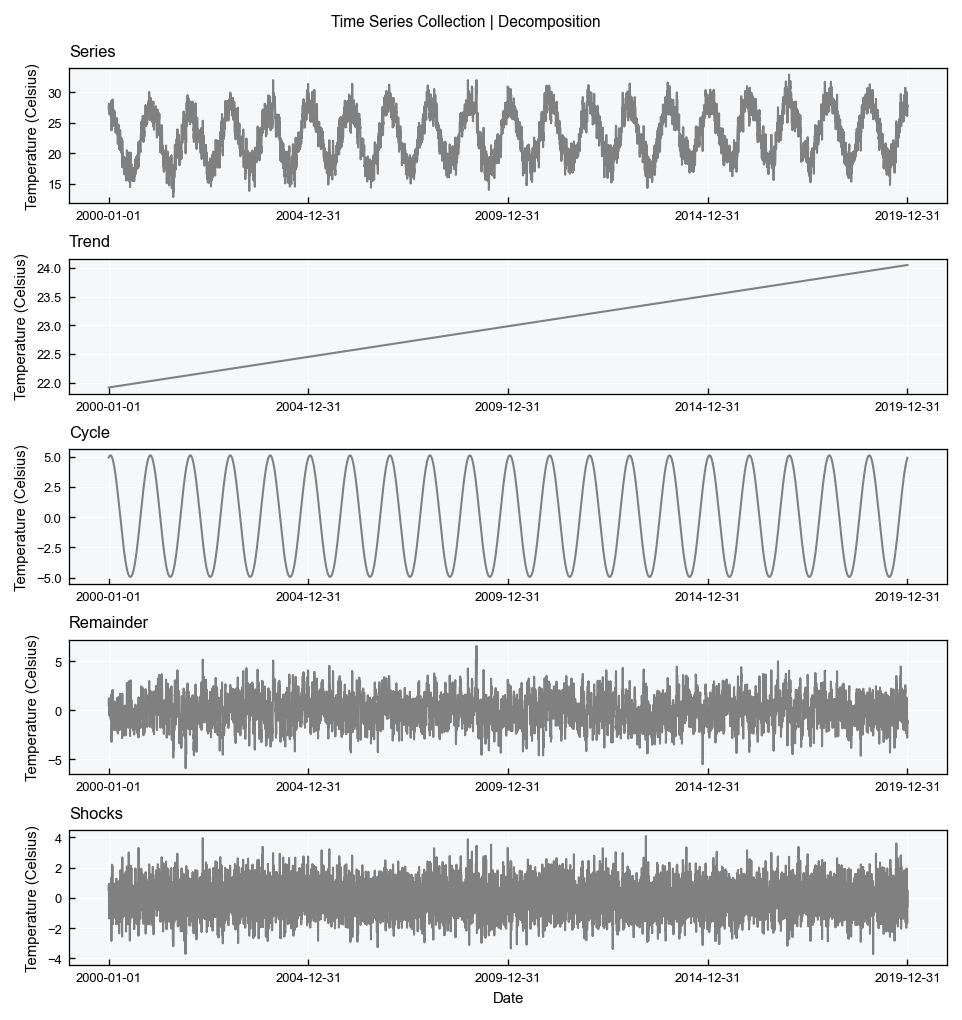

In [5]:
def make_series(df, field, name):
    # plain series of temperature from a column
    ts_new = TimeSeries(name=name, alias=name)
    ts_new.varname = "Temperature"
    ts_new.units = "Celsius"
    ts_new.set_data(input_df=df, input_dtfield="datetime", input_varfield=field)
    return ts_new

def make_collection(name, ls_series):
    tsc = TimeSeriesCollection(name=name)
    for ts_new in ls_series:
        tsc.append(new_object=ts_new)
    tsc.update(details=True)
    return tsc

df_parts["series"] = ts.data[ts.varfield].values
ls_panels = ["Series", "Trend", "Cycle", "Remainder", "Shocks"]

tsc_parts = make_collection(
    name="Decomposition",
    ls_series=[make_series(df=df_parts, field=s.lower(), name=s) for s in ls_panels],
)
tsc_parts.view_specs["layout"] = "stacked-simple"
tsc_parts.view_specs["panels"] = [[s] for s in ls_panels]
tsc_parts.view(show=True)

Nothing is lost. The trend, the cycle and the remainder add up to the series:

In [6]:
vct_sum = df_parts["trend"] + df_parts["cycle"] + df_parts["remainder"]
print(f"Largest difference: {np.abs(vct_sum - df_parts['series']).max():.2e} C")

Largest difference: 3.55e-15 C


The memory is the part of the remainder that does not come from the shocks. A closer look at one year shows how the remainder follows the memory, and how the shocks push it around:

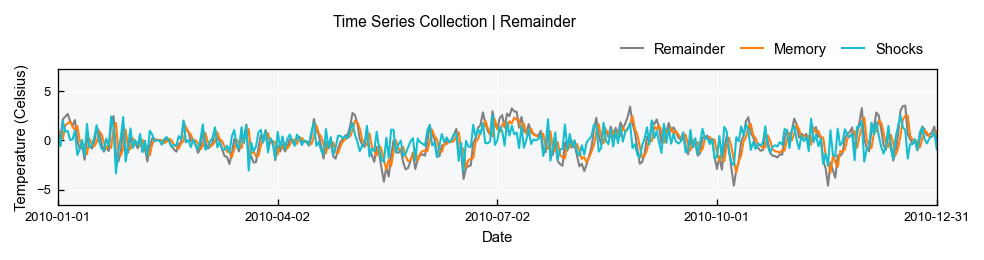

In [7]:
df_parts["memory"] = df_parts["remainder"] - df_parts["shocks"]
ls_panels = ["Remainder", "Memory", "Shocks"]

tsc_rem = make_collection(
    name="Remainder",
    ls_series=[make_series(df=df_parts, field=s.lower(), name=s) for s in ls_panels],
)
tsc_rem.view_specs["layout"] = "stacked-simple"
tsc_rem.view_specs["panels"] = [ls_panels]
tsc_rem.view_specs["xmin"] = pd.Timestamp("2010-01-01")
tsc_rem.view_specs["xmax"] = pd.Timestamp("2010-12-31")
tsc_rem.view(show=True)

## Fit

The `.fit()` method gives the parameters of the same model as a dictionary, and it leaves the data untouched. It works on a regular series without gaps. If the record has gaps, deal with them first using `.interpolate_gaps()`.

In [8]:
params = ts.fit()
params

{'start': 21.917108010205244,
 'slope': 0.0002924402071757246,
 'amplitude': 10.049533099187814,
 'period': 365.2425,
 'phase': 15.169431670471338,
 'power': 1.0462826759192567,
 'phi': 0.7125438865173589,
 'sigma': 1.0421041072881938,
 'origin': '2000-01-01 00:00:00',
 'freq': 'D'}

The trend comes as `start` and `slope`, the cycle as `amplitude`, `period`, `phase` and `power`, the memory as `phi` and the shocks as `sigma`. These are values per step, and `origin` and `freq` tell which dates they refer to. Converting them to the terms of `.generator_specs` shows how close the fit gets to the specs that made the data:

In [9]:
specs = ts.generator_specs
df_check = pd.DataFrame(
    {
        "specs": {
            "Trend change per year": specs["change_per_year"],
            "Cycle range": specs["topline"] - specs["baseline"],
            "Memory days": specs["memory_days"],
            "Remainder sd": specs["remainder_sd"],
        },
        "fit": {
            "Trend change per year": params["slope"] * params["period"],
            "Cycle range": params["amplitude"],
            "Memory days": -1 / np.log(params["phi"]),
            "Remainder sd": params["sigma"] / np.sqrt(1 - params["phi"] ** 2),
        },
    }
)
df_check.round(3)

,specs,fit
Trend change per year,0.1,0.107
Cycle range,10.0,10.050
Memory days,3.0,2.951
Remainder sd,1.5,1.485


## Build new series

The fitted parameters go back into `.generate()`. Since `origin` and `freq` are part of them, they work from any start date, and the trend and the cycle carry over. A new seed gives new shocks:

In [10]:
df_future = ts.generate(start="2020-01-01", end="2029-12-31", params=params, seed=2)
df_future.head()

,datetime,tas
0,2020-01-01,29.272041
1,2020-01-02,28.669198
2,2020-01-03,28.358947
3,2020-01-04,26.028630
4,2020-01-05,28.792039


To see the effect of one parameter, change it and generate again with the same seed. All series below use the same random numbers, so any difference comes from the change. Here is one perturbation of each part of the model, each on a panel with the fitted series:

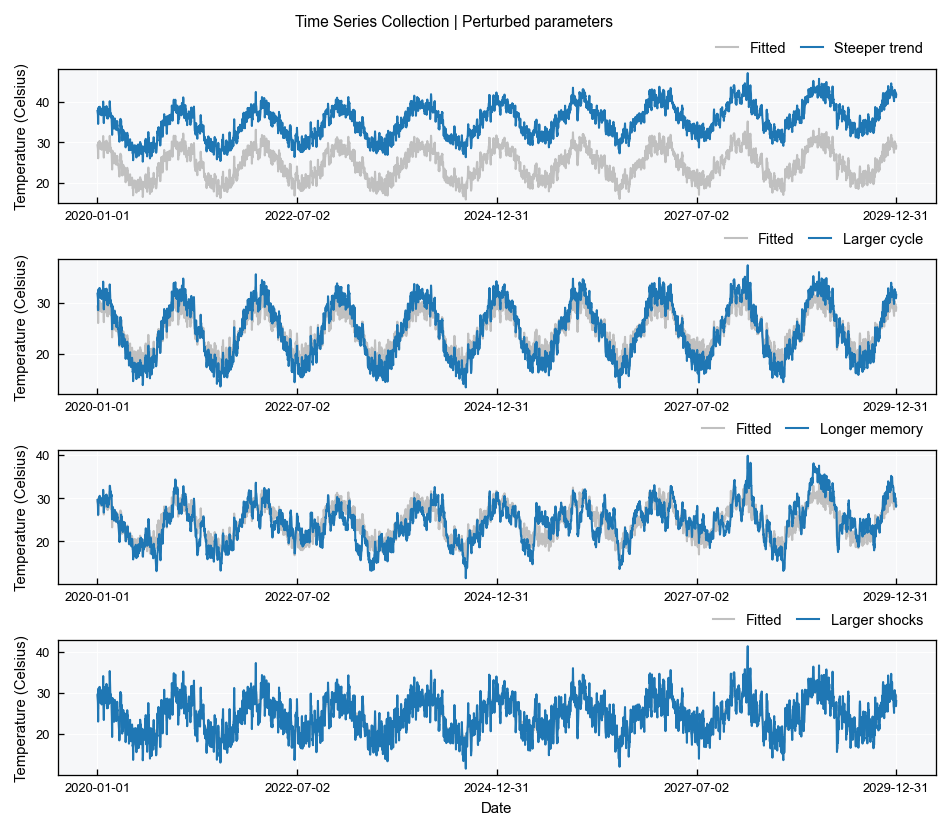

In [11]:
dc_changes = {
    "Steeper trend": {"slope": 5 * params["slope"]},
    "Larger cycle": {"amplitude": 1.5 * params["amplitude"]},
    "Longer memory": {"phi": 0.95},
    "Larger shocks": {"sigma": 2 * params["sigma"]},
}

def make_realization(name, params_new):
    df = ts.generate(start="2020-01-01", end="2029-12-31", params=params_new, seed=2)
    return make_series(df=df, field=ts.varfield, name=name)

ls_series = [make_realization(name="Fitted", params_new=params)]
for name, dc_change in dc_changes.items():
    ls_series.append(make_realization(name=name, params_new=dict(params, **dc_change)))

tsc_new = make_collection(name="Perturbed parameters", ls_series=ls_series)
# same color for the fitted series, and another for the perturbed ones
tsc_new.collection["Fitted"].view_specs["color"] = "silver"
for name in dc_changes:
    tsc_new.collection[name].view_specs["color"] = "tab:blue"
tsc_new.view_specs["layout"] = "stacked-simple"
tsc_new.view_specs["panels"] = [["Fitted", name] for name in dc_changes]
tsc_new.view(show=True)

The trend turns around the start of the fitted record, so a steeper one is already far away after 20 years. Note also that `phi` and `sigma` both change the size of the remainder, since its variance is $\sigma^2 / (1 - \varphi^2)$. A longer memory makes warm and cold spells last longer, and also makes them larger.

## Monte Carlo simulation

Now to a question that one series can not answer. How hot can a day get in 2030, if the process stays the same? A single realization gives one value. Many realizations give a distribution.

Here, each member has the same trend, cycle and memory, and its own random realization of the Gaussian shocks, which is what a different seed gives. A `TimeSeriesEnsemble` holds them:

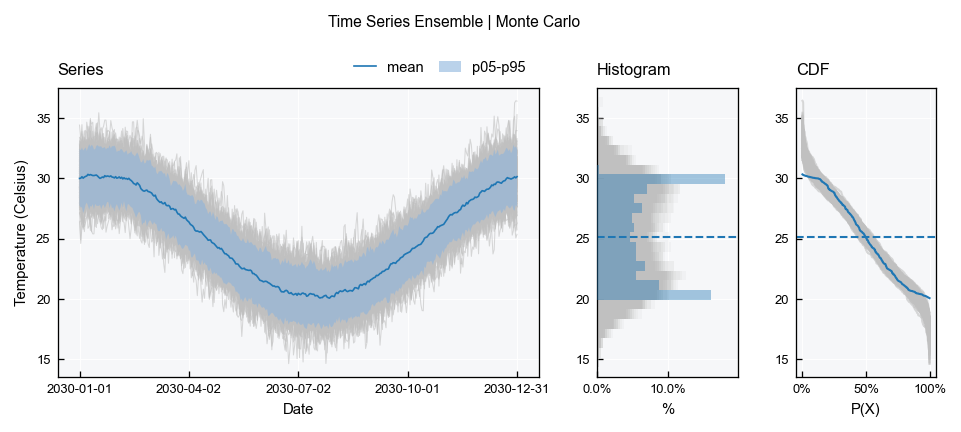

In [12]:
n_members = 200

tse = TimeSeriesEnsemble(name="Monte Carlo", base_object=TemperatureSeries)
for seed in range(n_members):
    name = f"R{seed + 1:03d}"
    ts_member = TemperatureSeries(name=name, alias=name)
    ts_member.set_data(
        input_df=ts.generate(start="2030-01-01", end="2030-12-31", params=params, seed=seed),
        input_dtfield=ts.dtfield,
        input_varfield=ts.varfield,
    )
    tse.append(new_object=ts_member)
tse.update(details=True)

tse.view_specs["bands"] = [[5, 95]]
tse.view_specs["reducers"] = ["mean"]
tse.view(show=True)

The mean of the members follows the trend and the cycle, and the width of the band comes from the remainder only. This can be checked. The spread between members at each step should match the standard deviation of the remainder:

In [13]:
vct_std = tse.std().iloc[:, 1].values
print(f"Spread between members: {vct_std.mean():.2f} C")
print(f"Remainder from the parameters: {params['sigma'] / np.sqrt(1 - params['phi'] ** 2):.2f} C")

Spread between members: 1.48 C
Remainder from the parameters: 1.49 C


Each member has its hottest day of the year. Together, they give the distribution of the answer:

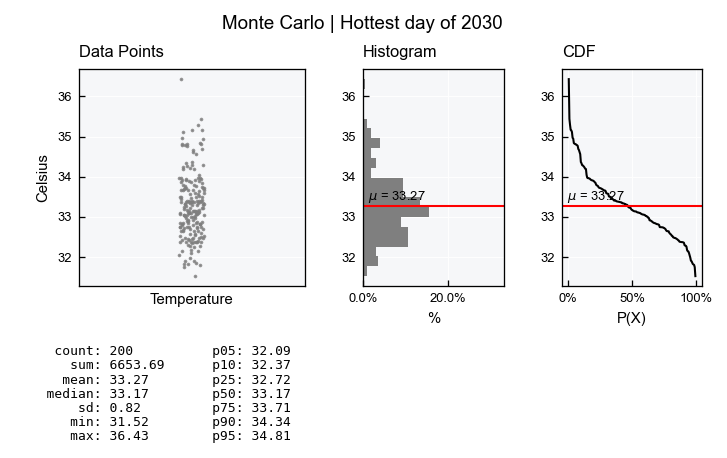

In [14]:
vct_max = np.array([tse.collection[n].data[ts.varfield].max() for n in tse.collection])

uv = Univar(name="Hottest day of 2030")
uv.varname = "Temperature"
uv.units = "Celsius"
uv.set_array(array=vct_max)
uv.view_specs["title"] = "Monte Carlo | Hottest day of 2030"
uv.view(show=True)

In [15]:
for threshold in [33, 34, 35]:
    print(f"P(hottest day > {threshold} C): {np.mean(vct_max > threshold):.1%}")

P(hottest day > 33 C): 62.0%
P(hottest day > 34 C): 14.5%
P(hottest day > 35 C): 3.0%


```{warning}
The members only differ by their shocks. The parameters are taken as known, while in practice they come with their own uncertainty, so this spread is a lower bound. The shocks are also Gaussian and additive, so the model does not fit variables with a skewed distribution as it fits temperature.
```

## Recap

- `.generate()` makes a series from physical specs in `.generator_specs`, or from parameters.
- `.decompose()` splits a series into trend, cycle, remainder and shocks. The remainder holds the memory and the shocks.
- `.fit()` estimates the parameters from a regular series without gaps, and they work from any start date.
- Changing a parameter and keeping the seed shows the effect of that parameter alone.
- Different seeds give different realizations of the shocks, and an ensemble of them makes a Monte Carlo simulation.